### Practice 3 - Notebook 1

# PCA with scikit-learn — Exercise 3

## Part 2: Wine Dataset — Plot PC1 Against PC3

In this exercise, we will use the Wine dataset and plot the **first principal component (PC1)** against the **third principal component (PC3)**.

The points will be colored by class so we can check whether the three wine classes still separate in this view.

**Question:** Do the classes still separate when we plot PC1 against PC3 instead of PC1 against PC2?

## Cell 1 — Import the Required Libraries

We need:
- `load_wine` to load the Wine dataset.
- `StandardScaler` to standardize the features.
- `PCA` to transform the standardized features into principal components.
- `matplotlib` to create the scatter plot.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## Cell 2 — Load the Wine Dataset

The dataset contains chemical measurements for wine samples. The target values identify the wine classes.

In [2]:
wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))

Dataset shape: (178, 13)
Number of features: 13
Number of classes: 3


## Cell 3 — Standardize the Features

PCA is affected by differences in feature scales. We standardize the features before applying PCA.

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (178, 13)


## Cell 4 — Apply PCA

Fit PCA to the standardized data and transform each wine sample into principal-component coordinates.

We will use PC1 for the horizontal axis and PC3 for the vertical axis.

In [4]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print("Transformed data shape:", X_pca.shape)
print("PC1 explained variance:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("PC3 explained variance:", round(pca.explained_variance_ratio_[2] * 100, 2), "%")

Transformed data shape: (178, 13)
PC1 explained variance: 36.2 %
PC3 explained variance: 11.12 %


## Cell 5 — Plot PC1 Against PC3

Each point represents one wine sample. The color indicates its class.

- The horizontal axis shows PC1.
- The vertical axis shows PC3.

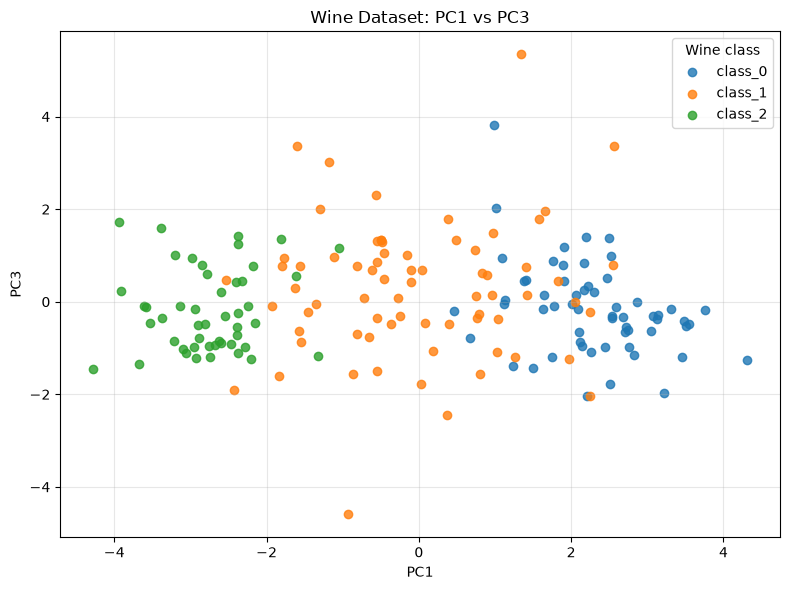

In [5]:
plt.figure(figsize=(8, 6))

for class_id, class_name in enumerate(wine.target_names):
    mask = y == class_id
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 2],
        label=class_name,
        alpha=0.8
    )

plt.xlabel("PC1")
plt.ylabel("PC3")
plt.title("Wine Dataset: PC1 vs PC3")
plt.legend(title="Wine class")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Final Answer

**Do the classes still separate?**

They still show some separation, especially along **PC1**, but the groups are not as clearly separated as they are in the PC1-versus-PC2 plot. Some samples from different classes overlap when PC1 is plotted against PC3.

**Conclusion:** Changing the vertical axis from PC2 to PC3 makes the class separation less clear. PC3 captures less variance than PC2, so this two-dimensional view contains less of the information that helps distinguish the classes.